# Airport Network Resilience to Major Hub Disruptions

### Objective
The goal of this study is to measure how much passenger traffic a U.S. airport network can carry when a major hub is temporarily closed. This could happen for many reasons including government shutdowns, TSA workers go without pay, air traffic control communication outage or extreme weather.

### Data
The data used in this study comes from the Bureau of Transportation Statistics <sup>[1](#ref1)</sup>. We focused on Delta Air Lines Network in 2025. The data was filtered to include only scheduled passenger service (Class F) operated by Delta Air Lines (DL) and it's subsidiary Endeavor Air (9E).

### Hub Selection
First we need to identify the airport that has the most siginificant passengers traffic including in transit or not in transit passengers, then select it as a major hub for this study.  

### Network Flow Optimization
To find the maximum network capacity, we model it as a flow graph in which airports are nodes and the flights are the arcs connecting them. Each arc has a capacity that is equal to the average number aviabale seats per day. Computing the maximum flow gives us insite into how many passengers can be rebooked onto alternative routes that bypasses the hub, and at the same time how many passengers will have their flight canceled anyway as the hub was the departure airport or the final destination. We can also identify the bottleneck arcs using the minimum cut; in other words, we reveale the saturated fights that will limit the maximum flow of people.

### Limitations and Use
Because the model ignores individual passenger destinations and connection timing, the results represent a best-case limit (an upper-bound) on a network capacity during a hub closure. It helps find the routes where adding seats (by replacing smaller aircraft with larger planes for example) or adding extra flights during a disruption would actually increase capacity.

---
<a id="ref1"></a>[1] Bureau of Transportation Statistics, [T-100 Domestic Segment data](https://transtats.bts.gov/DL_SelectFields.aspx?gnoyr_VQ=GEE&QO_fu146_anzr=Nv4%20Pn44vr45)

### Loading the raw data

In [277]:
import pandas as pd
import networkx as nx
import time
df = pd.read_csv("../data/raw/T_T100D_SEGMENT_ALL_CARRIER.csv")
df = df.sort_values("PASSENGERS",ascending=False)
df.head(15)

,SEATS,PASSENGERS,DISTANCE,AIR_TIME,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,CARRIER_NAME,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,DEST_AIRPORT_ID,DEST,DEST_CITY_NAME,AIRCRAFT_TYPE,MONTH,CLASS
458778,80388,74491,762,44557,DL,Delta Air Lines Inc.,Delta Air Lines Inc.,10397,ATL,"Atlanta, GA",12953,LGA,"New York, NY",699,5,F
458770,78699,72641,404,24600,DL,Delta Air Lines Inc.,Delta Air Lines Inc.,10397,ATL,"Atlanta, GA",13204,MCO,"Orlando, FL",622,10,F
458766,78074,72338,762,44316,DL,Delta Air Lines Inc.,Delta Air Lines Inc.,12953,LGA,"New York, NY",10397,ATL,"Atlanta, GA",699,7,F
458769,78696,71601,404,24882,DL,Delta Air Lines Inc.,Delta Air Lines Inc.,13204,MCO,"Orlando, FL",10397,ATL,"Atlanta, GA",622,10,F
458779,80634,71230,762,48303,DL,Delta Air Lines Inc.,Delta Air Lines Inc.,12953,LGA,"New York, NY",10397,ATL,"Atlanta, GA",699,5,F
458773,79078,68657,762,46170,DL,Delta Air Lines Inc.,Delta Air Lines Inc.,12953,LGA,"New York, NY",10397,ATL,"Atlanta, GA",699,8,F
458791,83456,68369,101,15359,HA,Hawaiian Airlines Inc.,Hawaiian Airlines Inc.,13830,OGG,"Kahului, HI",12173,HNL,"Honolulu, HI",608,7,F
458790,83456,68181,101,14210,HA,Hawaiian Airlines Inc.,Hawaiian Airlines Inc.,12173,HNL,"Honolulu, HI",13830,OGG,"Kahului, HI",608,7,F
458760,76119,67406,762,43282,DL,Delta Air Lines Inc.,Delta Air Lines Inc.,12953,LGA,"New York, NY",10397,ATL,"Atlanta, GA",699,6,F
458756,75648,67324,762,42775,DL,Delta Air Lines Inc.,Delta Air Lines Inc.,10397,ATL,"Atlanta, GA",12953,LGA,"New York, NY",699,6,F


### Filter the data and calculate the stats per day

In [278]:
#Keep only the delta flights in this study Detla Air and Endeavor Air Lines
delta = df[df["UNIQUE_CARRIER"].isin(["DL","9E"])]
delta = delta[delta["CLASS"] =="F"]
#Remove flights that never flew
delta = delta[delta["SEATS"]>0]
#Cleanup records where flights returned to the same airport
delta = delta[delta["ORIGIN"]!= delta["DEST"]]
#Calculate the capacity of each arc (route) by collapsing all the rows for each (Origin,Destintion) pair into a single row then calculate the avereage for each group.
routes = (
    delta.groupby(["ORIGIN","DEST"],as_index=False)
         .agg(SEATS_YEAR =("SEATS","sum"),
              PASSENGERS_YEAR=("PASSENGERS","sum"), 
              MEAN_DISTANCE=("DISTANCE","mean")))

#Convert yearly totals to an average day. Empty seats per day = rebooking capacity of the route
routes["SEATS_PER_DAY"] = routes["SEATS_YEAR"] / 365
routes["PASSENGERS_PER_DAY"] = routes["PASSENGERS_YEAR"] / 365
routes["EMPTY_PER_DAY"] = routes["SEATS_PER_DAY"] - routes["PASSENGERS_PER_DAY"] 
# Only consider flights that have empty seats
routes = routes[routes["EMPTY_PER_DAY"] > 0]
routes.head(10)

,ORIGIN,DEST,SEATS_YEAR,PASSENGERS_YEAR,MEAN_DISTANCE,SEATS_PER_DAY,PASSENGERS_PER_DAY,EMPTY_PER_DAY
0,ABE,ATL,78373,68091,692.0,214.720548,186.550685,28.169863
1,ABE,CAE,76,66,558.0,0.208219,0.180822,0.027397
2,ABE,EWR,76,70,67.0,0.208219,0.191781,0.016438
3,ABE,HPN,228,204,95.0,0.624658,0.558904,0.065753
4,ABE,LGA,882,694,83.0,2.416438,1.901370,0.515068
5,ABE,MDT,110,97,76.0,0.301370,0.265753,0.035616
6,ABE,TYS,76,69,572.0,0.208219,0.189041,0.019178
7,ABI,AUS,157,117,193.0,0.430137,0.320548,0.109589
8,ABI,SAT,109,89,211.0,0.298630,0.243836,0.054795
9,ABQ,ATL,176593,143243,1269.0,483.816438,392.446575,91.369863


### Revealing Hubs
Let's rank airports by their total daily seats (departures + arrivals).

In [279]:
# "seats_out" counts seats available on flights leaving from each airport
# "seats_in" counts seats available on flights arriving at each airport
# "hub_size" departing seats plus arriving seats for each airport
seats_out = routes.groupby("ORIGIN")["SEATS_PER_DAY"].sum()
seats_in  = routes.groupby("DEST")["SEATS_PER_DAY"].sum()
hub_size  = (seats_out.add(seats_in, fill_value=0)).sort_values(ascending=False)
hub_size.head(10)


ORIGIN
ATL    227840.049315
MSP     65853.731507
DTW     59505.265753
SLC     48275.967123
JFK     38616.147945
LGA     36402.934247
LAX     36067.712329
SEA     28631.556164
BOS     23414.504110
MCO     21845.052055
Name: SEATS_PER_DAY, dtype: float64

ATL is the airport with the largest total daily seat capacity on it's flights counting both departure and arrival. In the graph, ALT node has the largest weighted degree (sums of the numerical weights of those connected edges). Let's calculate it's share.

In [280]:
atl = routes[(routes["ORIGIN"] == "ATL") | (routes["DEST"] == "ATL")]
print(f"Share of Delta seats touching ATL: {atl['SEATS_YEAR'].sum() / routes['SEATS_YEAR'].sum():.1%}")

Share of Delta seats touching ATL: 45.0%


### Methodology

The maximum flow algorithm runs on a network made of nodes and arcs, where each arc links a pair of nodes and has a capacity. It requires a source node (S), where the flow starts, and a sink node (T), where the flow ends. The algorithm repeatedly sends units of flow from the source to the sink along paths that still have spare capacity. It stops when no such path is left, because the arcs that separate the source from the sink are full. These saturated arcs form the minimum cut.

In this study, we use the maximum flow algorithm to find the capacity of Delta Air Lines’ network when a hub is closed. To do so, we replace the hub node with a source node and a sink node. The source node sends a total flow equal to the number of passengers stranded by the canceled flights into the hub, starting from each of those flights’ origin airports. The sink node receives the passengers who were expected at the destinations of the canceled flights out of the hub. The maximum flow is therefore the largest number of stranded passengers who can reach their destinations using alternative routes that bypass the hub.

Below is an illustration of how we replace the hub node with a source node (S) and a sink node (T). The left chart shows a small network before the Atlanta hub (ATL) is closed. The right chart shows the same network after the ATL node is deleted, with a source node (S) and a sink node (T) added artificially so that the maximum flow algorithm can find alternative routes for the stranded passengers; 100 are in Boston going to Orlando and 80 are in Orlando going to Boston. Each canceled flight into ATL becomes an arc from S to that flight’s origin airport, and each canceled flight out of ATL becomes an arc from that flight’s destination airport to T. In both cases, the arc’s capacity equals the number of passengers on the canceled flight.

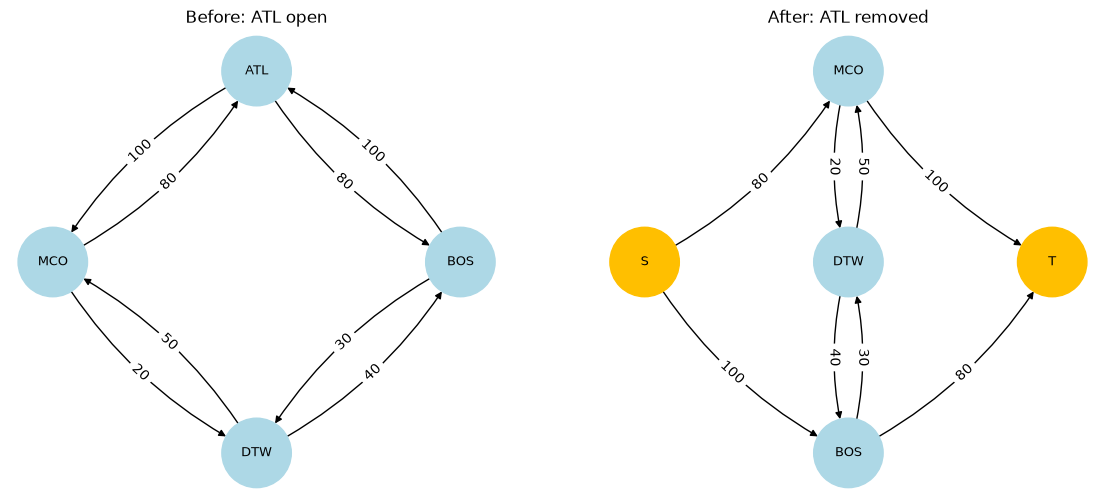

In [138]:
import networkx as nx
import matplotlib.pyplot as plt

# Graph Before: Atlanta is open
before = nx.DiGraph()
before.add_weighted_edges_from([
    ("BOS", "ATL", 100), ("ATL", "MCO", 100),   # 100 passengers BOS -> ATL -> MCO
    ("MCO", "ATL", 80),  ("ATL", "BOS", 80),    # 80 passengers MCO -> ATL -> BOS
    ("BOS", "DTW", 30),  ("DTW", "BOS", 40),    # empty seats
    ("MCO", "DTW", 20),  ("DTW", "MCO", 50),    # empty seats
], weight="capacity")

# Graph After: Atlanta removed, S and T added
after = before.copy()
after.remove_node("ATL")
after.add_weighted_edges_from([
    ("S", "BOS", 100), ("S", "MCO", 80),        # passengers stuck
    ("BOS", "T", 80),  ("MCO", "T", 100),       # passengers expected
], weight="capacity")

# Draw graphs side by side in a grid of charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

pos_before = nx.circular_layout(before)
# Display graph 2 in three columns style
pos_after = nx.multipartite_layout(after, subset_key={0: ["S"], 1: ["BOS", "DTW", "MCO"], 2: ["T"]})

for G, pos, ax, title in [(before, pos_before, axes[0], "Before: ATL open"),
                          (after, pos_after, axes[1], "After: ATL removed")]:
    colors = ["#FFBF00" if n in ("S", "T") else "lightblue" for n in G.nodes()]
    nx.draw(G, pos, ax=ax, with_labels=True, node_size=2500,font_size=9,
            node_color=colors, connectionstyle="arc3,rad=0.15")
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "capacity"),
                                 ax=ax, connectionstyle="arc3,rad=0.15")
    ax.set_title(title)
plt.show()

### Split the nodes

On the left, Boston is connected to both (S) and (T), so the algorithm can follow S $\rightarrow$ BOS $\rightarrow$ T. That counts a passenger as “arrived in Boston” when they never left Boston, never boarded a plane, never took an alternative route. The same happens at Orlando, so the left chart reports a flow max at 180, meaning all stranded passenger were rebooked. That is incorrect.

To avoid this issue, we split each airport into an arrival node and a departure node. The arc from an airport’s arrival node to its departure node represents passengers connecting at that airport, and it can have unlimited capacity.

The chart on the right, S $\rightarrow$ BOS_dep and BOS_arr $\rightarrow$ T touch different nodes, and there’s no arrow from BOS_dep to BOS_arr. The only way from a departure node to an arrival node is a flight. The shortcut is gone, and the max flow drops to 50, which is all the Detroit flights can carry (30 seats out of Boston + 20 out of Orlando).

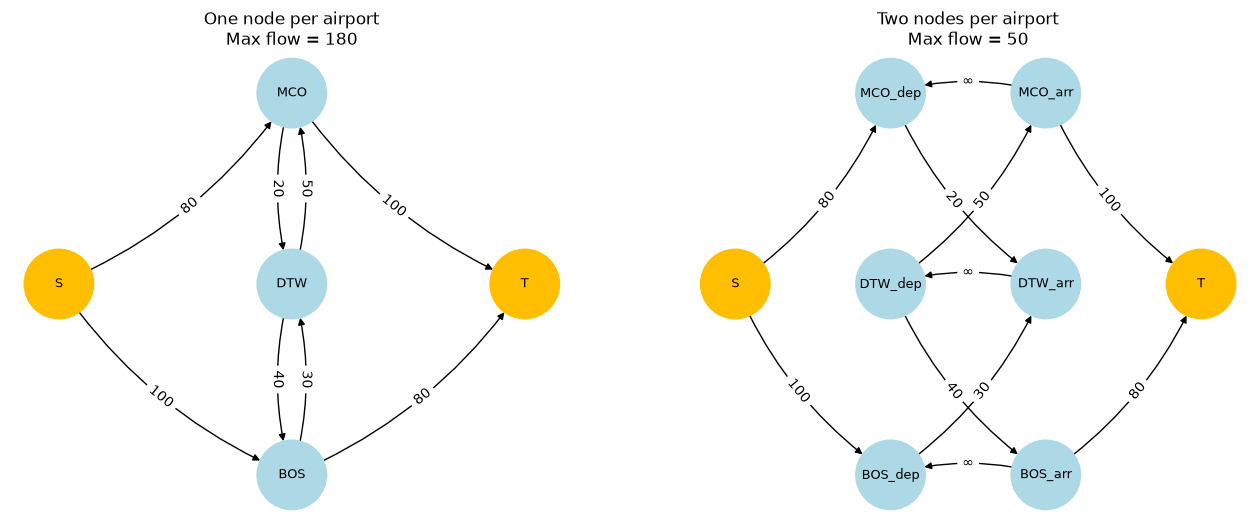

In [139]:
import networkx as nx
import matplotlib.pyplot as plt

# Graph 1 : Single node per airport
single = nx.DiGraph()
single.add_weighted_edges_from([
    ("S", "BOS", 100), ("S", "MCO", 80),          # passengers stuck
    ("BOS", "T", 80),  ("MCO", "T", 100),         # passengers expected
    ("BOS", "DTW", 30), ("DTW", "BOS", 40),       # flights (empty seats)
    ("MCO", "DTW", 20), ("DTW", "MCO", 50),
], weight="capacity")

# Graph 2: Split node for each airport
split = nx.DiGraph()
split.add_weighted_edges_from([
    ("S", "BOS_dep", 100), ("S", "MCO_dep", 80),             # S only goes to departures
    ("BOS_arr", "T", 80),  ("MCO_arr", "T", 100),            # T only comes from arrivals
    ("BOS_dep", "DTW_arr", 30), ("DTW_dep", "BOS_arr", 40),  # flights: dep -> arr
    ("MCO_dep", "DTW_arr", 20), ("DTW_dep", "MCO_arr", 50),
], weight="capacity")
split.add_edges_from([("BOS_arr", "BOS_dep"),               # Split nodes (connections)
                       ("DTW_arr", "DTW_dep"),              # capacity = infinity
                       ("MCO_arr", "MCO_dep")])              

# Display graph 1 in three columns style
pos_single = nx.multipartite_layout(single, subset_key={0: ["S"], 1: ["BOS", "DTW", "MCO"], 2: ["T"]})
# Display graph 2 in four columns style
pos_split = nx.multipartite_layout(split, subset_key={0: ["S"],
                                                        1: ["BOS_dep", "DTW_dep", "MCO_dep"],
                                                        2: ["BOS_arr", "DTW_arr", "MCO_arr"],
                                                        3: ["T"]})

# Draw graphs side by side, with the max flow in each title
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for G, pos, ax, title in [(single, pos_single, axes[0], "One node per airport"),
                          (double, pos_double, axes[1], "Two nodes per airport")]:
    # assign amber color for T and S, lightblue otherwise
    colors = ["#FFBF00" if n in ("S", "T") else "lightblue" for n in G.nodes()]
    #Display "∞" for connection flights, display arc capacity otherwise
    labels ={}
    for u,v,capa in G.edges(data= True):
        labels[(u,v)] = capa.get("capacity","∞")
        
    nx.draw(G, pos, ax=ax, with_labels=True, node_size=2500, font_size=9,
            node_color=colors, connectionstyle="arc3,rad=0.15")
    nx.draw_networkx_edge_labels(G, pos, labels,
                                 ax=ax, connectionstyle="arc3,rad=0.15")
    ax.set_title(f"{title}\nMax flow = {nx.maximum_flow_value(G, 'S', 'T')}")
plt.show()

### Build the Graph

The function below will build a directed graph given the routes, the hub and the share of the stranded passenger. In thise study we assume that 60% will be affected. 

In [281]:
def GraphBuilder(routes, hub, stranded_share):  
    
    # STRANDED connecting passengers stuck at their ORIGIN airport 
    into_hub = routes[routes["DEST"] == HUB][["ORIGIN", "PASSENGERS_PER_DAY"]].copy()
    into_hub["STRANDED"] = c * into_hub["PASSENGERS_PER_DAY"]
    
    # DEMAND = connecting passengers who want to reach each DESTINATION 
    out_hub = routes[routes["ORIGIN"] == HUB][["DEST", "PASSENGERS_PER_DAY"]].copy()
    out_hub["DEMAND"] = c * out_hub["PASSENGERS_PER_DAY"]
    
    print("Flights to Hub:", len(into_hub), "| Stranded per day:", round(into_hub["STRANDED"].sum()))
    print("Flights from Hub:", len(out_hub), "| Demand per day:", round(out_hub["DEMAND"].sum()))
    
    flights = routes[(routes["ORIGIN"] != HUB) & (routes["DEST"] != HUB)]
    print("Flights remaining:", len(flights))

    G = nx.DiGraph()
    # Flights: departure node to arrival node, capacity = empty seats per day
    for o, d, cap in zip(flights["ORIGIN"], flights["DEST"], flights["EMPTY_PER_DAY"]):
        G.add_edge(o + "_dep", d + "_arr", capacity=cap)
    
    # Connections: arrival to departure at the same airport. Unlimited passengers are authorized
    airports = set(routes["ORIGIN"]) | set(routes["DEST"])
    airports.discard(HUB)     # discard the closed Hub
    for a in airports:
        G.add_edge(a + "_arr", a + "_dep") 
    
    # Super source to origins, capacity = stranded passengers
    for a, s in zip(into_hub["ORIGIN"], into_hub["STRANDED"]):
        G.add_edge("S", a + "_dep", capacity=s)
    
    # Destinations to super sink, capacity = demand
    for a, dem in zip(out_hub["DEST"], out_hub["DEMAND"]):
        G.add_edge(a + "_arr", "T", capacity=dem)
    
    print("Nodes:", G.number_of_nodes(), "| Arcs:", G.number_of_edges())
    return G

HUB = "ATL"
c = 0.6   # 60% assumed share of ATL passengers who are connecting

G = GraphBuilder(routes,HUB,c)

Flights to Hub: 155 | Stranded per day: 57582
Flights from Hub: 165 | Demand per day: 57402
Flights remaining: 2656
Nodes: 414 | Arcs: 3182


### Stranded passengers with no alternative route

Let’s identify the number of passengers that can reach their destination only thougth Atlanta. With the hub closed, these passengers have no alternative route, so they will remain stranded until Atlanta reopens. To do so, we look for every direct flight to ATL and check whether its departure airport is connected to at least one airport. This can be done using a graph property called the out-degree of a node, which is the number of arcs leaving that node. A node with an out-degree of zero has no outgoing arcs.

In [282]:
atl_only = [a for a in into_atl["ORIGIN"] if G.out_degree(a + "_dep") == 0]
stuck = into_atl[into_atl["ORIGIN"].isin(atl_only)]["STRANDED"].sum()
print(f"Airports with no Delta flight except to ATL: {atl_only}")
print(f"{stuck:,.0f} passengers per day have no rebooking option at all")

Airports with no Delta flight except to ATL: ['ABY', 'DHN']
92 passengers per day have no rebooking option at all


### Solving the Maximum Flow Problem

In [300]:
def FlowMaxSolver(G):
    timer_start = time.perf_counter()
    max_flow = nx.maximum_flow_value(G, "S", "T")
    timer_end = time.perf_counter()
    elapsed =(timer_end - timer_start)
    total = into_atl["STRANDED"].sum()
    print(f"Rebooked per day: {max_flow:,.0f} passengers of {total:,.0f} stranded ({max_flow/total:.1%}) - elapsed {elapsed:,.1f} s")
    return max_flow
max_flow = FlowMaxSolver(G)

Rebooked per day: 28,717 passengers of 57,582 stranded (49.9%) - elapsed 0.1 s


The optimal maximum flow solution finds alternative routes for 49.7% of the stranded passengers. This means that some flights (arcs) in the network reach their full capacity and prevent the rest of the flow from moving from the source node to the sink node.

### The Bottleneck Flights 

Let’s find the flights that create a bottleneck and prevent all stranded passengers from reaching their destinations. This can be done by computing the minimum cut of the graph. A cut divides the nodes into two sets, one containing the source S and the other containing the sink T. The minimum cut is the cut for which the total capacity of the arcs going from the source side to the sink side is the smallest. By the max-flow min-cut theorem, this total equals the maximum flow, and the arcs crossing the cut are the saturated flights that limit it.

In [284]:
cut_value, (reachable, non_reachable) = nx.minimum_cut(G, "S", "T")
# Collect a list of tuples (arc, capacity) that have the departure node is the source side of the cut, 
# and the destination node in the sink side of the cut
cut_arcs = []
for u in reachable:
    for v in G[u]:
        if v in non_reachable:
            cap = G[u][v]["capacity"]
            f = flow[u][v]
            residual = cap - f
            cut_arcs.append((u,v,cap,f,residual))
            
print("Min cut value:", round(cut_value), "| Arcs in cut:", len(cut_arcs))

# Filter out artificial fights going out from S or going in T
def is_flight(x):
    return x[0] != "S" and x[1] != "T"
    
bottleneck_flight = sorted([x for x in cut_arcs if is_flight(x)], key=lambda x: x[2],reverse=True)
bottleneck_df = pd.DataFrame([x for x in bottleneck_flight], 
                            columns=["from","to","capacity","flow","residual"])
print("Top 10 Flights causing the bottleneck:")
bottleneck_df.head(10)

Min cut value: 28633 | Arcs in cut: 1722
Top 10 Flights causing the bottleneck:


,from,to,capacity,flow,residual
0,JFK_dep,FLL_arr,182.569863,182.569863,0.0
1,JFK_dep,MCO_arr,170.794521,170.794521,0.0
2,DTW_dep,FLL_arr,166.564384,166.564384,0.0
3,DTW_dep,ORD_arr,150.536986,150.536986,0.0
4,DTW_dep,DCA_arr,148.169863,148.169863,0.0
5,MSP_dep,DEN_arr,145.928767,145.928767,0.0
6,DTW_dep,CLT_arr,145.449315,145.449315,0.0
7,LAX_dep,AUS_arr,144.764384,144.764384,0.0
8,MSP_dep,MCO_arr,143.178082,143.178082,0.0
9,DTW_dep,MCO_arr,141.238356,141.238356,0.0


### Increase empty seasts for one of the minimum-cut

Let’s add empty seats to one of the cut arcs to try to increase the maximum flow. For example, we can pick the LAX $\rightarrow$ AUS flight and add an empty Airbus A350-900 with 306 seats.

In [293]:
routes_upg = routes.copy()
row = (routes_upg["ORIGIN"] == "LAX") & (routes_upg["DEST"] == "AUS")
routes_upg.loc[row, "EMPTY_PER_DAY"] = 306

G = GraphBuilder(routes_upg,HUB,c)
FlowMaxSolver(G)

Flights to Hub: 155 | Stranded per day: 57582
Flights from Hub: 165 | Demand per day: 57402
Flights remaining: 2656
Nodes: 414 | Arcs: 3182
Rebooked per day: 28,717 passengers of 57,582 stranded (49.9%) - elapsed 0.04007050002110191 s


28716.829041095876

Increasing the empty seats on the LAX $\rightarrow$  AUS flight did not significantly improve the total flow: only 112 additional passengers reached their destination. The LAX → AUS arc is in the minimum cut, so adding 306 seats to it let more passengers fly. However, after those 112 passengers, another arc on the same path filled up, became part of the new minimum cut and blocked the flow again at 28,717.

### Create a temporary Hub

Instead of increasing the capacity of the minimum cut arcs, we try this time to increase the maximum flow by adding flights through a temporary hub. In this example, BHM serves as the temporary hub and can handle 20% of Atlanta’s seats. We add arcs from the airports where passengers are stranded to BHM, and from BHM to the destinations, so passengers can be rerouted through it.

In [302]:
NEW_HUB = "BHM"   # temporary hub
SHARE = 0.2       # share of Atlanta's seats

#Helper function that adds capacity to arcs
def add_seats(graph, u, v, seats):
    if graph.has_edge(u, v):
        graph[u][v]["capacity"] += seats
    else:
        graph.add_edge(u, v, capacity=seats)

G_alt = G.copy()

#Creating new arcs from stranded passengers’ airports to the new hub
to_atl = routes[routes["DEST"] == HUB]     
for index,row in to_atl.iterrows():
    origine = row["ORIGIN"]
    seats = row["SEATS_PER_DAY"]
    if origine != NEW_HUB:
        add_seats(G_alt, origine + "_dep", NEW_HUB + "_arr", SHARE * seats)  
        
#Creating new arcs from new hub to stranded passengers’ airports 
from_atl = routes[routes["ORIGIN"] == HUB] 
for _,row in from_atl.iterrows():
    destination = row["DEST"]
    seats = row["SEATS_PER_DAY"]
    if destination != NEW_HUB:
        add_seats(G_alt, NEW_HUB + "_dep", destination + "_arr", SHARE * seats)  
        
# Run MaxFlow
new_flow = nx.maximum_flow_value(G_alt, "S", "T")

print(f" Temporary hub \"{NEW_HUB}\" at {SHARE:.0%}: Max flow {new_flow:,.0f} - rerouted {new_flow - max_flow:,.0f}")

 Temporary hub "BHM" at 20%: Max flow 44,850 - rerouted 16,133


## Conclusions

If the Atlanta hub closes, Delta’s network can reroute at most 28,633 of the 57,582 stranded passengers per day (49.7%), based on average 2025 data. Because the flow network ignores individual passenger destinations and flight schedules, this is a best-case upper bound. The rest of the passengers are limited by saturated flights, identified by the minimum cut, or by airports connected to the network only through Atlanta. These flights are where temporary measures, such as larger aircraft or extra flights, would most increase the number of passengers who could be rerouted. Adding a temporary hub can reroute considerably more stranded passengers than upgrading individual flights, but this depends on the airport being able to handle the extra traffic.